In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
# load the csv
df = pd.read_csv("battery_data.csv")

arr = df.to_numpy()
minutes_arr = arr[:,0]
life_arr = arr[:,0]

<function matplotlib.pyplot.show(close=None, block=None)>

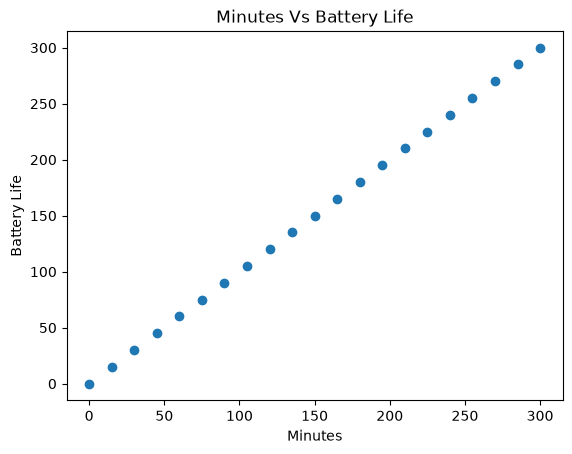

In [10]:
plt.scatter(minutes_arr, life_arr)
plt.title("Minutes Vs Battery Life")
plt.xlabel("Minutes")
plt.ylabel("Battery Life")
plt.show

In [5]:
# cost calculation

def cost(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> float:    
    f_wb = w * x_i + b
    sum = (f_wb - y_i) ** 2
    sum = np.sum(sum)
    cost = sum / (2 * len(x_i))
    return cost

In [6]:
def gradient(x_i: np.ndarray, y_i: np.ndarray, w: float, b: float) -> tuple:
    f_wb = w * x_i + b
    sum_b = f_wb - y_i
    sum_w = sum_b * x_i
    sum_w = np.sum(sum_w)
    sum_b = np.sum(sum_b)

    grad_w = sum_w / (len(x_i))
    grad_b = sum_b / (len(x_i))
    return grad_w, grad_b

In [11]:
# change w and b simultaneously until we done

def lin_regression(x_i: np.ndarray, y_i: np.ndarray, alpha: float, cost, gradient) -> tuple:
    costs = []
    parameters = []
    w = 0
    b = 0
    prev_cost = 0
    curr_cost = cost(x_i, y_i, w, b)
    iters = 0
    while (abs(prev_cost - curr_cost) > 0.0000001):
        prev_cost = curr_cost
        grad_w, grad_b = gradient(x_i, y_i, w, b)
        w = w - alpha * grad_w
        b = b - alpha * grad_b
        curr_cost = cost(x_i, y_i, w, b)
        costs.append(curr_cost)
        parameters.append([w, b])
        if iters % 30000 == 0:
            print(f"iter: {iters} w: {w} b: {b} cost: {curr_cost}")
        iters += 1            
    return w, b, costs, parameters

In [12]:
w_final, b_final, costs, parameters = lin_regression(minutes_arr, life_arr, 0.000065, cost, gradient)
print(w_final, b_final)

iter: 0 w: 1.9987499999999998 b: 0.00975 cost: 15338.047242843746
0.9999274629766708 0.004227760790857091


IndexError: list index out of range

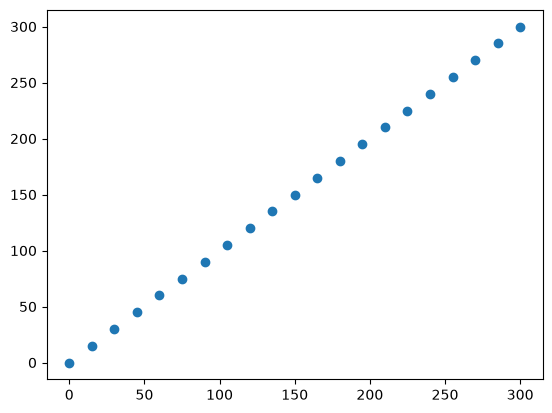

In [9]:
plt.scatter(minutes_arr, life_arr)
for i in range(10000, 200000, 20000):
    plt.plot(minutes_arr, parameters[i][0]*minutes_arr + parameters[i][1], color="red", label="model")
plt.title("Minutes Vs Battery Life")
plt.xlabel("Minutes")
plt.ylabel("Battery Life")
plt.show()